In [29]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# File paths
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/Global_fragment_size_proportions.csv'
tf_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_500kb_NST.csv'

# Load data
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Optional: Check column names
print(frag_df.columns)
print(tf_df.columns)


Index(['Sample', 'Subnucleosomal_90_150', 'Mononucleosomal_151_250',
       'Dinucleosomal_251_450', 'Trinucleosomal_451_650'],
      dtype='object')
Index(['Sample', 'Tumor_fraction_500kb bin'], dtype='object')


In [30]:
# Step 1: Load data (if not already loaded)
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)
tf_df.rename(columns={'Tumor_fraction_500kb bin': 'Tumor_fraction'}, inplace=True)

# Step 2: Get sets of sample names
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

# Step 3: Find intersection and differences
matched_samples = frag_samples & tf_samples
only_in_frag = frag_samples - tf_samples
only_in_tf = tf_samples - frag_samples

# Step 4: Print counts
print(f"Total samples in fragmentation file: {len(frag_samples)}")
print(f"Total samples in TFx file: {len(tf_samples)}")
print(f"Matched samples in both: {len(matched_samples)}")
print(f"Samples only in fragmentation file: {len(only_in_frag)}")
print(f"Samples only in TFx file: {len(only_in_tf)}")

# Optional: Save unmatched samples to CSV for review
pd.DataFrame(sorted(only_in_frag), columns=['Unmatched_in_TFx']).to_csv('only_in_fragmentation.csv', index=False)
pd.DataFrame(sorted(only_in_tf), columns=['Unmatched_in_fragmentation']).to_csv('only_in_tfx.csv', index=False)

# Assuming frag_df and tf_df are already loaded
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

only_in_frag = frag_samples - tf_samples

# Display them
print("Samples only in fragmentation file (missing in TFx):")
for s in sorted(only_in_frag):
    print(s)

Total samples in fragmentation file: 262
Total samples in TFx file: 262
Matched samples in both: 262
Samples only in fragmentation file: 0
Samples only in TFx file: 0
Samples only in fragmentation file (missing in TFx):


In [20]:
# Merge and export the final dataset
merged_df = pd.merge(tf_df, frag_df, on='Sample', how='inner')

# Optional: sort for readability
merged_df = merged_df.sort_values(by='Tumor_fraction', ascending=False)

# Save
merged_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/merged_TFx_hg38_500kb_fragmentation.csv', index=False)


In [21]:
from scipy.stats import pearsonr, spearmanr

# Basic correlation (linear and rank-based)
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

print(f"🔹 Pearson correlation: r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.4e}")
print(f"🔹 Spearman correlation: rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.4e}")


🔹 Pearson correlation: r = 0.4857, p = 6.4627e-17
🔹 Spearman correlation: rho = 0.3994, p = 1.8767e-11


In [22]:
import statsmodels.api as sm

# Prepare regression inputs
X = merged_df['Tumor_fraction']
y = merged_df['Subnucleosomal_90_150']
X = sm.add_constant(X)  # Adds intercept

# Fit model
model = sm.OLS(y, X).fit()
print(model.summary())


                              OLS Regression Results                             
Dep. Variable:     Subnucleosomal_90_150   R-squared:                       0.236
Model:                               OLS   Adj. R-squared:                  0.233
Method:                    Least Squares   F-statistic:                     80.28
Date:                   Wed, 15 Oct 2025   Prob (F-statistic):           6.46e-17
Time:                           14:39:21   Log-Likelihood:                 494.39
No. Observations:                    262   AIC:                            -984.8
Df Residuals:                        260   BIC:                            -977.6
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. Each point represents a patient plasma sample (n=262). Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) was derived from global cfDNA fragmentation profiles. A moderate positive correlation was observed (Pearson r = 0.4857, p = 6.5e-17), indicating that higher tumor burden is associated with increased cfDNA fragmentation. The regression line is shown in red.
--------------------------------------------------------------------------------


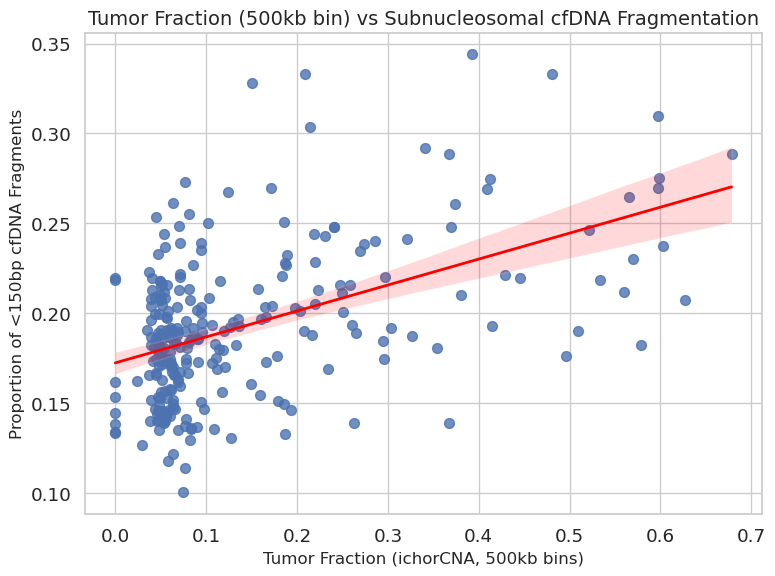

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# -----------------------------
# Step 1: Load the merged dataset
# -----------------------------
# Make sure this path points to your cleaned merged file
merged_df = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/merged_TFx_hg38_500kb_fragmentation.csv')

# Optional: clean sample names (if needed)
merged_df['Sample'] = merged_df['Sample'].astype(str).str.strip()

# -----------------------------
# Step 2: Correlation Analysis
# -----------------------------
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

# -----------------------------
# Step 3: OLS Regression
# -----------------------------
X = sm.add_constant(merged_df['Tumor_fraction'])
y = merged_df['Subnucleosomal_90_150']
model = sm.OLS(y, X).fit()

# -----------------------------
# Step 4: Save stats to CSV
# -----------------------------
stats_summary = {
    "Pearson_r": [pearson_corr[0]],
    "Pearson_p": [pearson_corr[1]],
    "Spearman_rho": [spearman_corr.correlation],
    "Spearman_p": [spearman_corr.pvalue],
    "OLS_Intercept": [model.params['const']],
    "OLS_Slope": [model.params['Tumor_fraction']],
    "OLS_p_value": [model.pvalues['Tumor_fraction']],
    "R_squared": [model.rsquared],
    "Adj_R_squared": [model.rsquared_adj]
}
stats_df = pd.DataFrame(stats_summary)
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_500kb_fragmentation_stats.csv', index=False)

# -----------------------------
# Step 5: Generate Publication-Quality Plot
# -----------------------------
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8, 6))
sns.regplot(
    data=merged_df,
    x='Tumor_fraction',
    y='Subnucleosomal_90_150',
    scatter_kws={'s': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'lw': 2}
)
plt.title('Tumor Fraction (500kb bin) vs Subnucleosomal cfDNA Fragmentation', fontsize=14)
plt.xlabel('Tumor Fraction (ichorCNA, 500kb bins)', fontsize=12)
plt.ylabel('Proportion of <150bp cfDNA Fragments', fontsize=12)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_500kb_vs_fragmentation_plot.png', dpi=300)

# -----------------------------
# Step 6: Print Figure Caption
# -----------------------------
caption = (
    f"Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. "
    f"Each point represents a patient plasma sample (n={len(merged_df)}). "
    f"Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) "
    f"was derived from global cfDNA fragmentation profiles. "
    f"A moderate positive correlation was observed (Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.1e}), "
    f"indicating that higher tumor burden is associated with increased cfDNA fragmentation. "
    f"The regression line is shown in red."
)

print("\n" + "-"*80)
print("-"*80)
print(caption)
print("-"*80)


In [33]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# File paths
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/Global_fragment_size_proportions.csv'
tf_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_1000kb_NST.csv'

# Load data
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Optional: Check column names
print(frag_df.columns)
print(tf_df.columns)


Index(['Sample', 'Subnucleosomal_90_150', 'Mononucleosomal_151_250',
       'Dinucleosomal_251_450', 'Trinucleosomal_451_650'],
      dtype='object')
Index(['Sample', 'Tumor_fraction_1000kb bin'], dtype='object')


In [34]:
# Step 1: Load data (if not already loaded)
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)
tf_df.rename(columns={'Tumor_fraction_1000kb bin': 'Tumor_fraction'}, inplace=True)

# Step 2: Get sets of sample names
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

# Step 3: Find intersection and differences
matched_samples = frag_samples & tf_samples
only_in_frag = frag_samples - tf_samples
only_in_tf = tf_samples - frag_samples

# Step 4: Print counts
print(f"Total samples in fragmentation file: {len(frag_samples)}")
print(f"Total samples in TFx file: {len(tf_samples)}")
print(f"Matched samples in both: {len(matched_samples)}")
print(f"Samples only in fragmentation file: {len(only_in_frag)}")
print(f"Samples only in TFx file: {len(only_in_tf)}")

# Optional: Save unmatched samples to CSV for review
pd.DataFrame(sorted(only_in_frag), columns=['Unmatched_in_TFx']).to_csv('only_in_fragmentation.csv', index=False)
pd.DataFrame(sorted(only_in_tf), columns=['Unmatched_in_fragmentation']).to_csv('only_in_tfx.csv', index=False)

# Assuming frag_df and tf_df are already loaded
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

only_in_frag = frag_samples - tf_samples

# Display them
print("Samples only in fragmentation file (missing in TFx):")
for s in sorted(only_in_frag):
    print(s)

Total samples in fragmentation file: 262
Total samples in TFx file: 262
Matched samples in both: 262
Samples only in fragmentation file: 0
Samples only in TFx file: 0
Samples only in fragmentation file (missing in TFx):


In [35]:
# Merge and export the final dataset
merged_df = pd.merge(tf_df, frag_df, on='Sample', how='inner')

# Optional: sort for readability
merged_df = merged_df.sort_values(by='Tumor_fraction', ascending=False)

# Save
merged_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/merged_TFx_hg38_1000kb_fragmentation.csv', index=False)


In [36]:
from scipy.stats import pearsonr, spearmanr

# Basic correlation (linear and rank-based)
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

print(f"🔹 Pearson correlation: r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.4e}")
print(f"🔹 Spearman correlation: rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.4e}")


🔹 Pearson correlation: r = 0.5140, p = 4.5722e-19
🔹 Spearman correlation: rho = 0.4100, p = 4.8412e-12


In [37]:
import statsmodels.api as sm

# Prepare regression inputs
X = merged_df['Tumor_fraction']
y = merged_df['Subnucleosomal_90_150']
X = sm.add_constant(X)  # Adds intercept

# Fit model
model = sm.OLS(y, X).fit()
print(model.summary())

                              OLS Regression Results                             
Dep. Variable:     Subnucleosomal_90_150   R-squared:                       0.264
Model:                               OLS   Adj. R-squared:                  0.261
Method:                    Least Squares   F-statistic:                     93.34
Date:                   Wed, 15 Oct 2025   Prob (F-statistic):           4.57e-19
Time:                           15:08:49   Log-Likelihood:                 499.33
No. Observations:                    262   AIC:                            -994.7
Df Residuals:                        260   BIC:                            -987.5
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. Each point represents a patient plasma sample (n=262). Tumor fraction was estimated using ichorCNA (1000kb bin size), and the proportion of short DNA fragments (<150bp) was derived from global cfDNA fragmentation profiles. A moderate positive correlation was observed (Pearson r = 0.5140, p = 4.6e-19), indicating that higher tumor burden is associated with increased cfDNA fragmentation. The regression line is shown in red.
--------------------------------------------------------------------------------


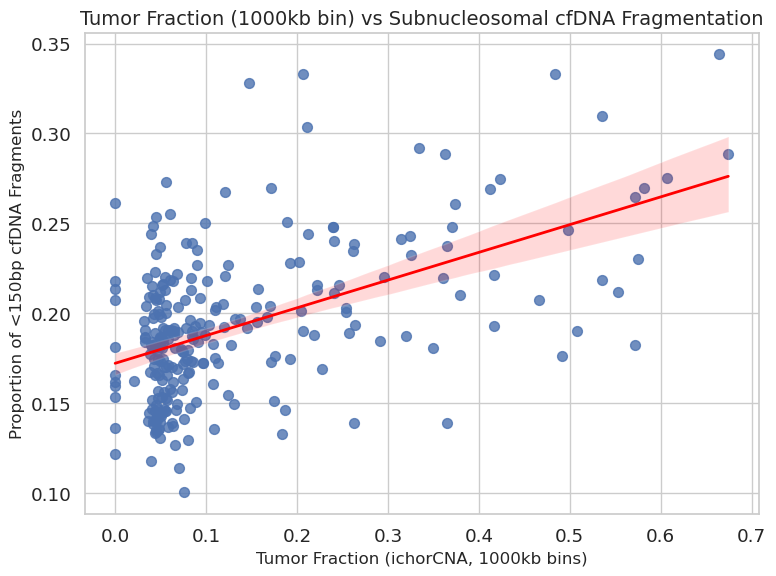

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# -----------------------------
# Step 1: Load the merged dataset
# -----------------------------
# Make sure this path points to your cleaned merged file
merged_df = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/merged_TFx_hg38_1000kb_fragmentation.csv')

# Optional: clean sample names (if needed)
merged_df['Sample'] = merged_df['Sample'].astype(str).str.strip()

# -----------------------------
# Step 2: Correlation Analysis
# -----------------------------
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

# -----------------------------
# Step 3: OLS Regression
# -----------------------------
X = sm.add_constant(merged_df['Tumor_fraction'])
y = merged_df['Subnucleosomal_90_150']
model = sm.OLS(y, X).fit()

# -----------------------------
# Step 4: Save stats to CSV
# -----------------------------
stats_summary = {
    "Pearson_r": [pearson_corr[0]],
    "Pearson_p": [pearson_corr[1]],
    "Spearman_rho": [spearman_corr.correlation],
    "Spearman_p": [spearman_corr.pvalue],
    "OLS_Intercept": [model.params['const']],
    "OLS_Slope": [model.params['Tumor_fraction']],
    "OLS_p_value": [model.pvalues['Tumor_fraction']],
    "R_squared": [model.rsquared],
    "Adj_R_squared": [model.rsquared_adj]
}
stats_df = pd.DataFrame(stats_summary)
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_1000kb_fragmentation_stats.csv', index=False)

# -----------------------------
# Step 5: Generate Publication-Quality Plot
# -----------------------------
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8, 6))
sns.regplot(
    data=merged_df,
    x='Tumor_fraction',
    y='Subnucleosomal_90_150',
    scatter_kws={'s': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'lw': 2}
)
plt.title('Tumor Fraction (1000kb bin) vs Subnucleosomal cfDNA Fragmentation', fontsize=14)
plt.xlabel('Tumor Fraction (ichorCNA, 1000kb bins)', fontsize=12)
plt.ylabel('Proportion of <150bp cfDNA Fragments', fontsize=12)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_1000kb_vs_fragmentation_plot.png', dpi=300)

# -----------------------------
# Step 6: Print Figure Caption
# -----------------------------
caption = (
    f"Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. "
    f"Each point represents a patient plasma sample (n={len(merged_df)}). "
    f"Tumor fraction was estimated using ichorCNA (1000kb bin size), and the proportion of short DNA fragments (<150bp) "
    f"was derived from global cfDNA fragmentation profiles. "
    f"A moderate positive correlation was observed (Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.1e}), "
    f"indicating that higher tumor burden is associated with increased cfDNA fragmentation. "
    f"The regression line is shown in red."
)

print("\n" + "-"*80)
print("-"*80)
print(caption)
print("-"*80)


🔹 Pearson r = 0.9652, p = 1.72e-153
🔹 Spearman rho = 0.8727, p = 6.52e-83
                            OLS Regression Results                            
Dep. Variable:             TFx_1000kb   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.931
Method:                 Least Squares   F-statistic:                     3543.
Date:                Wed, 15 Oct 2025   Prob (F-statistic):          1.72e-153
Time:                        15:31:52   Log-Likelihood:                 495.34
No. Observations:                 262   AIC:                            -986.7
Df Residuals:                     260   BIC:                            -979.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

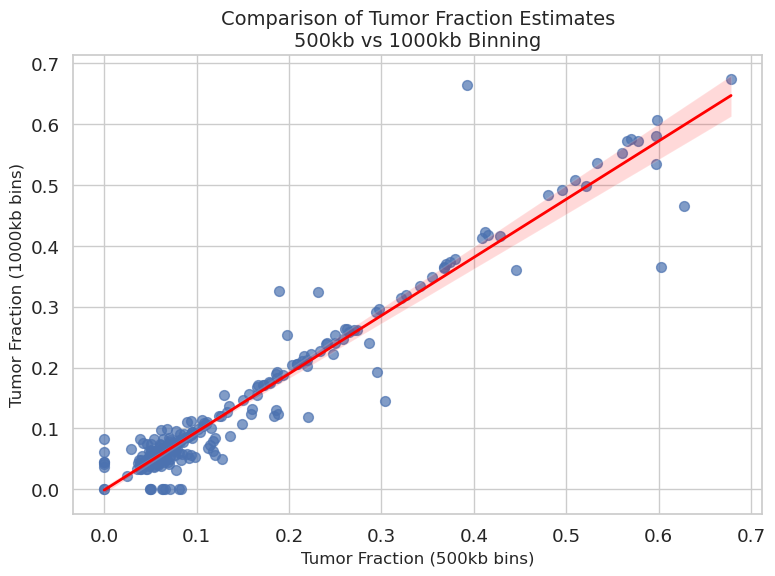

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# Load both TFx files
tfx_500kb = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_500kb_NST.csv')
tfx_1000kb = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_1000kb_NST.csv')

# Clean and rename
tfx_500kb.columns = ['Sample', 'TFx_500kb']
tfx_1000kb.columns = ['Sample', 'TFx_1000kb']

# Strip any whitespace
tfx_500kb['Sample'] = tfx_500kb['Sample'].str.strip()
tfx_1000kb['Sample'] = tfx_1000kb['Sample'].str.strip()

# Merge
tfx_merged = pd.merge(tfx_500kb, tfx_1000kb, on='Sample', how='inner')

# Save merged data
tfx_merged.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/tfx_500kb_vs_1000kb.csv', index=False)

# Correlation
pearson_corr = pearsonr(tfx_merged['TFx_500kb'], tfx_merged['TFx_1000kb'])
spearman_corr = spearmanr(tfx_merged['TFx_500kb'], tfx_merged['TFx_1000kb'])

print(f"🔹 Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.2e}")
print(f"🔹 Spearman rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.2e}")

# Regression for reference
X = sm.add_constant(tfx_merged['TFx_500kb'])
y = tfx_merged['TFx_1000kb']
model = sm.OLS(y, X).fit()

# Plot
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8,6))
sns.regplot(
    data=tfx_merged,
    x='TFx_500kb',
    y='TFx_1000kb',
    scatter_kws={'s': 50, 'alpha': 0.7},
    line_kws={'color': 'red', 'lw': 2}
)
plt.xlabel('Tumor Fraction (500kb bins)', fontsize=12)
plt.ylabel('Tumor Fraction (1000kb bins)', fontsize=12)
plt.title('Comparison of Tumor Fraction Estimates\n500kb vs 1000kb Binning', fontsize=14)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_500kb_vs_1000kb_plot.png', dpi=300)

# Print regression summary
print(model.summary())

# --------------------------------------------
# Save correlation and regression stats to CSV
# --------------------------------------------
stats_summary = {
    'Pearson_r': [pearson_corr[0]],
    'Pearson_p': [pearson_corr[1]],
    'Spearman_rho': [spearman_corr.correlation],
    'Spearman_p': [spearman_corr.pvalue],
    'OLS_Intercept': [model.params['const']],
    'OLS_Slope': [model.params['TFx_500kb']],
    'OLS_p_value': [model.pvalues['TFx_500kb']],
    'R_squared': [model.rsquared],
    'Adj_R_squared': [model.rsquared_adj]
}

stats_df = pd.DataFrame(stats_summary)

# Save to file
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/tfx_bin_comparison_stats.csv', index=False)
print("\n Stats saved to tfx_bin_comparison_stats.csv")


🔎 Found 26 samples with TFx(1000kb) - TFx(500kb) > 0.05


count    26.000000
mean      0.191175
std       0.177169
min       0.025380
25%       0.040654
50%       0.154125
75%       0.253925
max       0.566200
Name: TFx_avg, dtype: float64

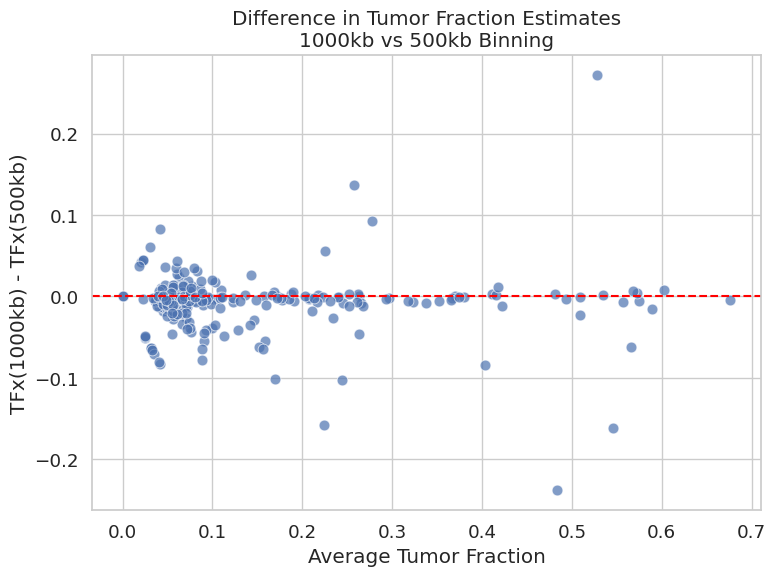

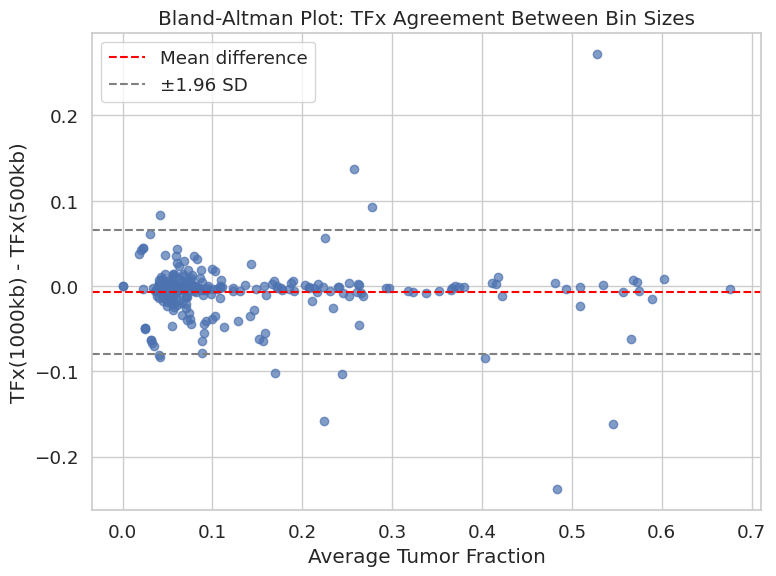

In [46]:
tfx_merged['TFx_diff'] = tfx_merged['TFx_1000kb'] - tfx_merged['TFx_500kb']
# Compute average TFx per sample
tfx_merged['TFx_avg'] = (tfx_merged['TFx_500kb'] + tfx_merged['TFx_1000kb']) / 2

# Scatterplot
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.scatterplot(data=tfx_merged, x='TFx_avg', y='TFx_diff', alpha=0.7, s=60)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Average Tumor Fraction')
plt.ylabel('TFx(1000kb) - TFx(500kb)')
plt.title('Difference in Tumor Fraction Estimates\n1000kb vs 500kb Binning')
plt.grid(True)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_bin_difference_vs_avgTFx.png', dpi=300)

# Absolute difference > 0.05
large_diff = tfx_merged[abs(tfx_merged['TFx_diff']) > 0.05]

# Save list
large_diff.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/samples_with_large_TFx_disagreement.csv', index=False)

print(f"🔎 Found {len(large_diff)} samples with TFx(1000kb) - TFx(500kb) > 0.05")

# Bland-Altman, To assess agreement and bias
mean = tfx_merged['TFx_avg']
diff = tfx_merged['TFx_diff']

plt.figure(figsize=(8,6))
plt.scatter(mean, diff, alpha=0.7)
plt.axhline(diff.mean(), color='red', linestyle='--', label='Mean difference')
plt.axhline(diff.mean() + 1.96*diff.std(), color='gray', linestyle='--', label='±1.96 SD')
plt.axhline(diff.mean() - 1.96*diff.std(), color='gray', linestyle='--')
plt.xlabel('Average Tumor Fraction')
plt.ylabel('TFx(1000kb) - TFx(500kb)')
plt.title('Bland-Altman Plot: TFx Agreement Between Bin Sizes')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/bland_altman_TFx_bin_comparison.png', dpi=300)

# Where do these samples fall in TFx range
large_diff['TFx_avg'].describe()

✅ Correlation analysis complete. Saved to fragmentation_vs_TFx_correlations.csv


/software/rhel9/manual/install/python/ondemand-jupyter-python3.11-2023.09/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


📊 Plot saved to fragmentation_vs_TFx_plot.png


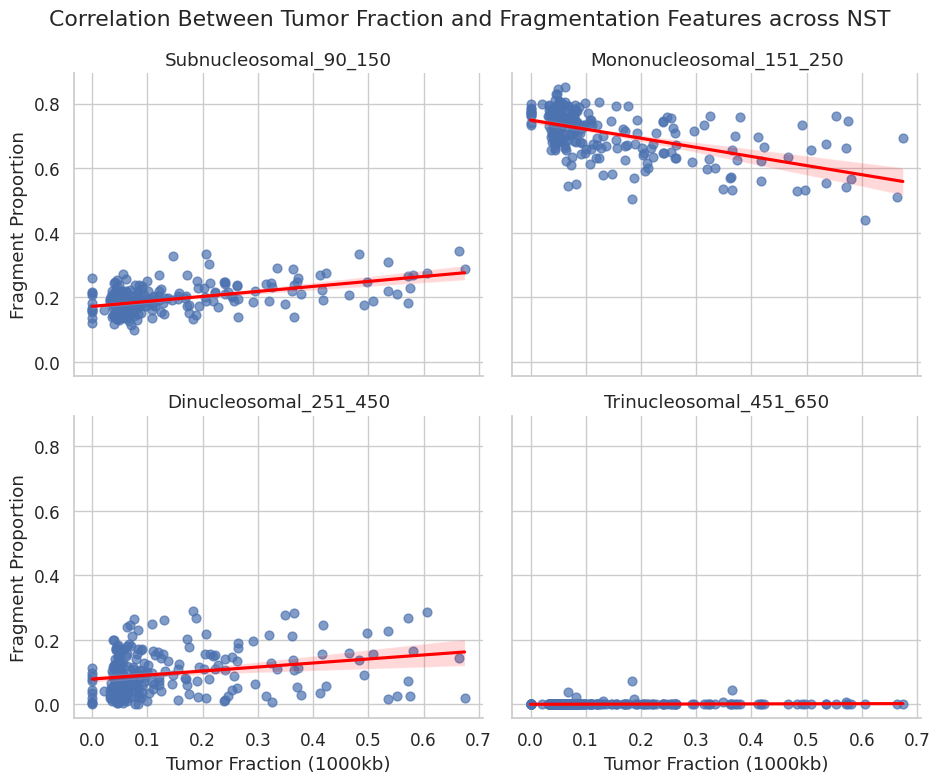

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# -------------------------
# Step 1: Load the data
# -------------------------

# Load fragmentation proportions
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/Global_fragment_size_proportions.csv'
frag_df = pd.read_csv(frag_path)

# Load TFx (1000kb)
tfx_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/TFx_hg38_1000kb_NST.csv'
tfx_df = pd.read_csv(tfx_path)
tfx_df.columns = ['Sample', 'Tumor_fraction']
tfx_df['Sample'] = tfx_df['Sample'].str.strip()
frag_df['Sample'] = frag_df['Sample'].str.strip()

# Merge datasets
merged_df = pd.merge(tfx_df, frag_df, on='Sample', how='inner')

# -------------------------
# Step 2: Correlation Analysis
# -------------------------

fragment_features = [
    'Subnucleosomal_90_150',
    'Mononucleosomal_151_250',
    'Dinucleosomal_251_450',
    'Trinucleosomal_451_650'
]

correlation_results = []

for feature in fragment_features:
    pearson_r, pearson_p = pearsonr(merged_df['Tumor_fraction'], merged_df[feature])
    spearman_rho, spearman_p = spearmanr(merged_df['Tumor_fraction'], merged_df[feature])
    correlation_results.append({
        'Fragment_feature': feature,
        'Pearson_r': pearson_r,
        'Pearson_p': pearson_p,
        'Spearman_rho': spearman_rho,
        'Spearman_p': spearman_p
    })

# Convert to DataFrame and save
corr_df = pd.DataFrame(correlation_results)
corr_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/fragmentation_vs_TFx_correlations.csv', index=False)

print("✅ Correlation analysis complete. Saved to fragmentation_vs_TFx_correlations.csv")

# -------------------------
# Step 3: Plotting
# -------------------------

# Reshape for faceted plot
long_df = merged_df.melt(
    id_vars='Tumor_fraction',
    value_vars=fragment_features,
    var_name='Fragment_Type',
    value_name='Proportion'
)

# Plot: TFx vs Fragment Proportions
sns.set(style="whitegrid", font_scale=1.1)
g = sns.lmplot(
    data=long_df,
    x='Tumor_fraction',
    y='Proportion',
    col='Fragment_Type',
    col_wrap=2,
    height=4,
    aspect=1.2,
    scatter_kws={'s': 40, 'alpha': 0.7},
    line_kws={'color': 'red'}
)
g.set_titles('{col_name}')
g.set_axis_labels("Tumor Fraction (1000kb)", "Fragment Proportion")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Correlation Between Tumor Fraction and Fragmentation Features across NST")
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/fragmentation_vs_TFx_plot.png', dpi=300)

print("📊 Plot saved to fragmentation_vs_TFx_plot.png")


In [4]:
import pandas as pd
import os

# === Configuration ===
input_file = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ichorCNA_longitudinal_summaries/1000kb_NST.csv"
output_dir = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/ichorCNA"
output_file = os.path.join(output_dir, "ichorCNA_correlation.csv")

# === Metrics to analyze ===
ichorCNA_metrics = [
    "Tumor_fraction",
    "Ploidy",
    "Subclonal_fraction",
    "Frac_Genome_Subclonal",
    "Frac_CNA_Subclonal"
]

# === Load Data ===
df = pd.read_csv(input_file)

# === Filter rows with any ichorCNA metric available ===
df_metrics = df.dropna(subset=ichorCNA_metrics, how='all')

# === Count how many samples have metrics ===
num_samples = df_metrics.shape[0]
print(f"Number of samples with at least one ichorCNA metric: {num_samples}")

# === Compute correlation matrix ===
correlation_matrix = df_metrics[ichorCNA_metrics].corr()

# === Save correlation matrix ===
os.makedirs(output_dir, exist_ok=True)
correlation_matrix.to_csv(output_file)

print(f"Correlation matrix saved to: {output_file}")



Number of samples with at least one ichorCNA metric: 260
Correlation matrix saved to: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/ichorCNA/ichorCNA_correlation.csv


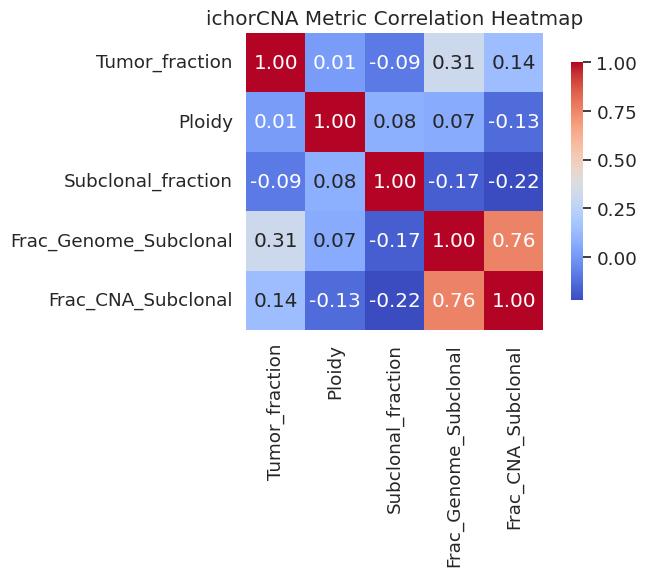

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# === Config ===
correlation_csv = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/ichorCNA/ichorCNA_correlation.csv"
output_dir = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Corelation/ichorCNA"
output_png = os.path.join(output_dir, "ichorCNA_correlation_heatmap.png")
output_pdf = os.path.join(output_dir, "ichorCNA_correlation_heatmap.pdf")

# === Load correlation matrix ===
corr_matrix = pd.read_csv(correlation_csv, index_col=0)

# === Plot heatmap ===
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
heatmap = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("ichorCNA Metric Correlation Heatmap")
plt.tight_layout()

# === Save ===
plt.savefig(output_png, dpi=300)
plt.savefig(output_pdf)

# === Display on screen ===
plt.show()
